# Phân loại Bình luận Spam / Ham trên Mạng Xã hội FB

Thử nghiệm pipeline phân loại bình luận (comments) tiếng Việt thành 2 nhóm:
* **Ham**: Bình luận bình thường, thảo luận hợp lệ của người dùng.
* **Spam**: Bình luận rác, chèo kéo bán hàng, quảng cáo, cờ bạc, lừa đảo hoặc chứa liên kết độc hại.

Pipeline thực nghiệm gồm các bước:
1. **Khám phá và phân tích dữ liệu (EDA)**
2. **Tiền xử lý văn bản chuyên biệt (Data Preprocessing)**
3. **Trích xuất đặc trưng & Biểu diễn vector (Feature Engineering)**
4. **Huấn luyện mô hình học máy (Model Training)**
5. **Đánh giá mô hình (Model Evaluation)**

## Thiết lập Môi trường và Thư viện


In [1022]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from underthesea import word_tokenize
from gensim.models import Word2Vec
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer    
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from scipy.sparse import hstack

pd.set_option('display.max_colwidth', None) # Show full text 

## 1. Khám phá Dữ liệu (Exploratory Data Analysis - EDA)


### Đọc tập dữ liệu tự gán nhãn

In [1023]:
df = pd.read_csv('auto_labeled_comments.csv')

### Kiểm tra kích thước và kiểu dữ liệu
1. **Dataset Shape**: Số lượng hàng (mẫu) và số lượng cột (thuộc tính).
2. **Non-Null Count**: Kiểm tra giá trị khuyết thiếu (missing values) trên các trường dữ liệu.

In [1024]:
print('Dataset Shape:', df.shape)
df.info()

Dataset Shape: (4161, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4161 entries, 0 to 4160
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   content  4161 non-null   object
 1   label    4161 non-null   object
dtypes: object(2)
memory usage: 65.1+ KB


### Xem một số mẫu dữ liệu ngẫu nhiên

In [1025]:
df.head(10)

,content,label
0,"k chăm chỉ là đc e, lên là các thầy cho vào ngay",ham
1,Phan Bảo Hai Anh neu m biet m se biet,ham
2,Tôi có,ham
3,giỏi,ham
4,Xứt sắc,ham
5,@nêu bật à tui còn có cả cuốn Kinh tế lượng nữa ạ. Các bé vô quẹo lựa nha,ham
6,Cho pass vs,ham
7,Tadv dễ hơn em ạ,ham
8,Có cả chống gian lận trên lms cơ à=))) PTIT đầu tư ác thế,ham
9,Tẹt ga,ham


### Khảo sát các mẫu bình luận Spam thực tế

In [1026]:
df[df["label"]=="spam"].head(5)

,content,label
18,b đưa sđt đây,spam
19,Hỗ Trợ Làm ED ib page này nhanh nhất nhé,spam
22,Dạ bạn thi ở 281 Khuất Duy Tiến i.b mình hỗ trợ nhé. Bạn có thể check trang FB của mình cho yên tâm ạ,spam
30,cô Kim Dung aptis,spam
31,"Tui đang gom nhóm học để đc giảm hphi, bạn học thì ib nhé",spam


### Thống kê phân bố nhãn (Class Distribution)
* Khảo sát tỷ lệ giữa nhãn `ham` và `spam` để xác định mức độ chênh lệch nhãn của bài toán.

In [1027]:
df['label'].value_counts()

label
ham     3580
spam     581
Name: count, dtype: int64

### Trực quan hóa phân bố nhãn bằng biểu đồ cột

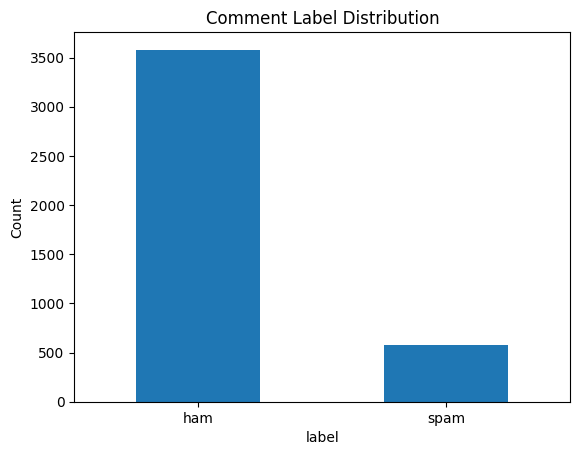

In [1028]:
df['label'].value_counts().plot(kind='bar', rot=0)
plt.title('Comment Label Distribution')
plt.ylabel('Count')
plt.show()

### Phân tích độ dài ký tự của bình luận theo nhãn
* **Boxplot**: So sánh phân vị, trung vị và các giá trị ngoại lai (outliers) về độ dài ký tự giữa bình luận bình thường và bình luận spam.

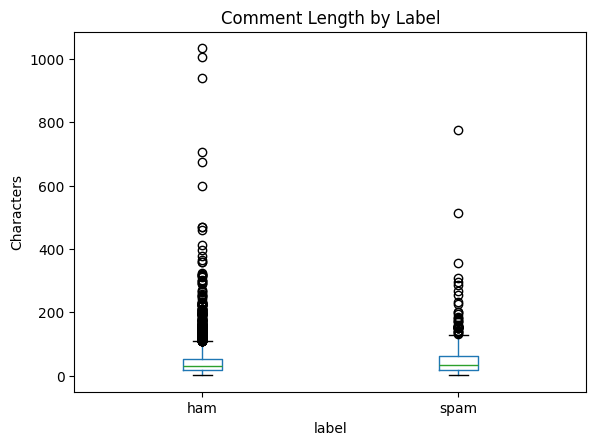

In [1029]:
df['char_len'] = df['content'].astype(str).str.len()
df.boxplot(column='char_len', by='label', grid=False)
plt.title('Comment Length by Label')
plt.suptitle('')
plt.ylabel('Characters')
plt.show()

## 2. Tiền Xử Lý Dữ Liệu (Data Preprocessing)
  1. **Chuyển chữ thường (Lowercasing)**: Đồng nhất chữ hoa, chữ thường.
  2. **Tokenization chuyên biệt**: Quy đổi đường link (`token_url`), số điện thoại (`token_sdt`), và từ khóa liên hệ/mời gọi (`token_lienhe` như ib, zalo, sđt) thành các Token đặc trưng đại diện.
  3. **Lọc ký tự đặc biệt**: Giữ lại ký tự chữ và số.
  4. **Tách từ tiếng Việt**: Sử dụng công cụ `underthesea` để ghép các từ ghép (VD: "bán_hàng", "liên_hệ").
  5. **Loại bỏ Stopwords**: Lọc bỏ các từ dừng - từ có tần số cao nhưng ít mang giá trị phân biệt ngữ nghĩa.

### Định nghĩa hàm tiền xử lý văn bản

In [1030]:
STOPWORDS = {'là', 'thì', 'và', 'của', 'những', 'các', 'một', 'được', 'với', 'ở', 'này', 'đó', 'cho'}

def preprocess(text):
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' token_url ', text)
    text = re.sub(r'(?:(?:\+|00)?84|0)(?:\d[\s\.]?){8,10}\d', ' token_sdt ', text)
    text = re.sub(r'\b(i[\.\s]?b|inbox|inb|zalo|zl|lh|liên hệ)\b', ' token_lienhe ', text)
    text = re.sub(r'[^\w\s]', ' ', text)
    tokens = word_tokenize(text, format='text').split()
    return ' '.join(w for w in tokens if w not in STOPWORDS)

### Áp dụng tiền xử lý lên toàn bộ tập dữ liệu

In [1031]:
df['processed'] = df['content'].apply(preprocess)
df[['content', 'processed', 'label']].head(10)

,content,processed,label
0,"k chăm chỉ là đc e, lên là các thầy cho vào ngay",k chăm_chỉ đc e lên thầy vào ngay,ham
1,Phan Bảo Hai Anh neu m biet m se biet,phan_bảo hai anh neu m biet m se biet,ham
2,Tôi có,tôi có,ham
3,giỏi,giỏi,ham
4,Xứt sắc,xứt sắc,ham
5,@nêu bật à tui còn có cả cuốn Kinh tế lượng nữa ạ. Các bé vô quẹo lựa nha,nêu bật à tui còn có cả cuốn kinh_tế lượng nữa ạ bé vô_quẹo lựa nha,ham
6,Cho pass vs,pass vs,ham
7,Tadv dễ hơn em ạ,tadv dễ hơn em ạ,ham
8,Có cả chống gian lận trên lms cơ à=))) PTIT đầu tư ác thế,có cả chống gian_lận trên lms cơ à ptit đầu_tư ác_thế,ham
9,Tẹt ga,tẹt ga,ham


### Phân Chia Tập Dữ Liệu (Train / Test Split)
1. **Tỷ lệ phân chia**: 80% tập huấn luyện (Train) và 20% tập kiểm thử (Test).
2. **Stratified Sampling (`stratify=df['label']`)**: Bảo toàn tỷ lệ phân bố giữa nhãn ham và spam tương đồng trên cả 2 tập, tránh bias khi đánh giá trên tập dữ liệu mất cân bằng.

In [1032]:
train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=42, stratify=df['label'])
train = df.loc[train_idx].copy()
test = df.loc[test_idx].copy()
pd.DataFrame({'Train': train['label'].value_counts(), 'Test': test['label'].value_counts()})

,Train,Test
label,,
ham,2863,717
spam,465,116


## 3. Trích Xuất Đặc Trưng & Biểu Diễn Vector (Feature Engineering)
* Nghiên cứu so sánh 4 không gian biểu diễn đặc trưng văn bản khác nhau:
  1. **Bag of Words (BoW)**: Biểu diễn tần số xuất hiện từ và cụm từ (1-gram, 2-gram).
  2. **TF-IDF**: Trọng số hóa tần số từ theo nghịch đảo tần số văn bản.
  3. **Word2Vec Averaging**: Biểu diễn ngữ nghĩa phân tán (dense semantic embedding) bằng trung bình cộng vector từ.
  4. **Word2Vec TF-IDF Weighted**: Trung bình có trọng số IDF nhằm ưu tiên các từ mang tính đặc thù cao hơn.
  5. **Hybrid (TF-IDF + Word2Vec)**: Kết hợp vector n-gram thưa và vector ngữ nghĩa đặc bằng phép ghép nối (concatenation/hstack).

### Mô hình Bag-of-Words (BoW / N-gram Count)
* Cấu hình: `ngram_range=(1, 2)` (kết hợp cả unigram và bigram), loại bỏ các từ chỉ xuất hiện 1 lần (`min_df=2`).

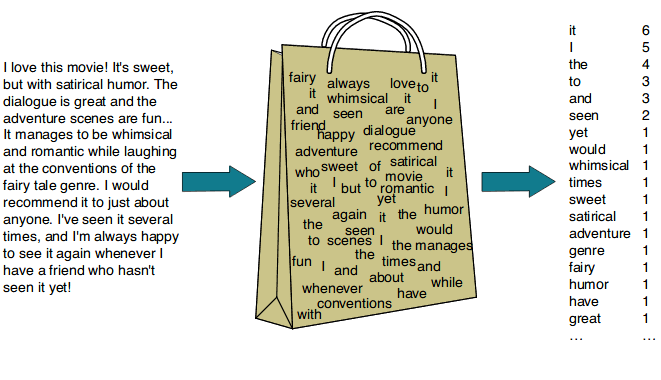

In [1033]:
vec_bow = CountVectorizer(ngram_range=(1, 2), min_df=2)
X_train_bow = vec_bow.fit_transform(train['processed'])
X_test_bow = vec_bow.transform(test['processed'])
print('BoW Vocabulary Size:', X_train_bow.shape[1])

BoW Vocabulary Size: 4417


### Khảo sát danh sách đặc trưng BoW

In [1034]:
feature_names = vec_bow.get_feature_names_out()
print("100 đặc trưng đầu:")
print(feature_names[:100])
print("\n100 đặc trưng cuối:")
print(feature_names[-100:])

100 đặc trưng đầu:
['000' '000 người' '000 tháng' '08' '08 2026' '09' '09 2026' '10' '10 20'
 '10 em' '10 học' '10 mới' '10 tr' '10 vào' '100' '100 000' '100 câu'
 '100 nghe' '100 phòng' '103' '11' '12' '120' '128' '13' '130' '14'
 '14 tín' '145' '15' '150' '16' '17' '18' '18 tuổi' '19' '19 e04' '20'
 '20 người' '200' '200 câu' '200 người' '2006' '2024' '2025' '2026'
 '2026 2027' '2027' '21' '216' '22' '220' '223' '225' '225 990' '225 mới'
 '23' '24' '25' '250' '255' '255 nguyễn_văn_trỗi' '28' '30' '30 nha'
 '30 nhé' '300' '316' '336' '35' '35 khối' '36' '40' '40 câu' '40 người'
 '400' '50' '500' '542' '60' '600' '601' '70' '700' '730' '730 toeic'
 '730 đổi' '80' '90' '95' '990' '993' '993 dạ' 'a1' 'a2' 'a2 nhé' 'a_cx'
 'ac' 'ac chỉ' 'ac có']

100 đặc trưng cuối:
['địa_chỉ trường' 'địa_phương' 'địa_điểm' 'định' 'định_hướng' 'đọc'
 'đọc kỹ' 'đọc lại' 'đọc nhé' 'đỏ' 'đối' 'đối_ngoại' 'đối_ngoại mpc'
 'đối_nội' 'đối_nội gen' 'đối_nội sẽ' 'đối_tượng' 'đối_với' 'đồ'
 'đồ cơ_bản' 'đồ thể_tha

### Trích xuất mẫu vector BoW của 1 bình luận

In [1035]:
print("Raw:", train.iloc[36]["content"])
print("Processed:", train.iloc[36]["processed"])
print("Vector BoW:", X_train_bow[36].toarray())
np.savetxt("out/vector_bow.txt", X_train_bow[36].toarray().ravel(), fmt="%.6f")
print("Shape:", X_train_bow[36].shape)

Raw: Em có thể tham khảo Aptis nha, Aptis là dễ nhất rùi , em học trong thời gian ngắn là thi đc , em cần tham khảo nhắn sốp nha
Processed: em có_thể tham_khảo aptis nha aptis dễ nhất rùi em học trong thời_gian ngắn thi đc em cần tham_khảo nhắn_sốp nha
Vector BoW: [[0 0 0 ... 0 0 0]]
Shape: (1, 4417)


### Mô hình TF-IDF (Term Frequency - Inverse Document Frequency)
* Cấu hình: `ngram_range=(1, 2)`, `min_df=2`, bật `sublinear_tf=True` (thay thế $tf$ bằng $1 + \log(tf)$) giúp làm dịu ảnh hưởng của các từ lặp lại nhiều lần.

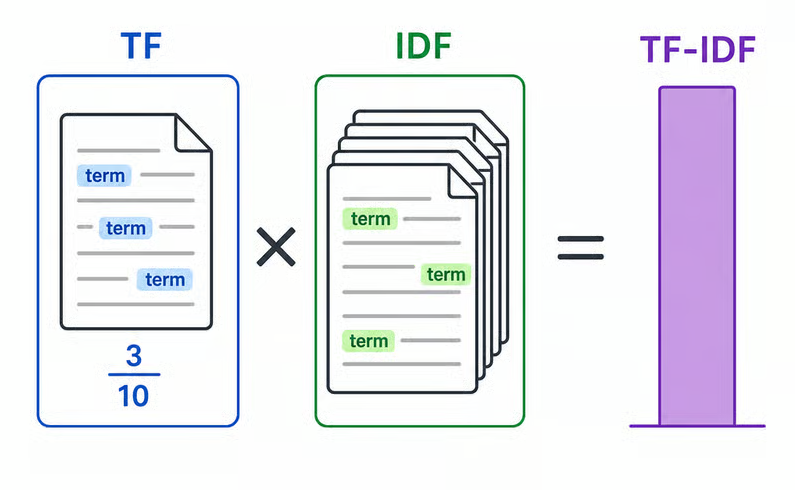

In [1036]:
vec_tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_tfidf = vec_tfidf.fit_transform(train['processed'])
X_test_tfidf = vec_tfidf.transform(test['processed'])
print('TF-IDF Features Size:', X_train_tfidf.shape[1])

TF-IDF Features Size: 4417


### Khảo sát danh sách đặc trưng TF-IDF

In [1037]:
feature_names = vec_tfidf.get_feature_names_out()
print("100 đặc trưng đầu:", feature_names[:100])
print("100 đặc trưng cuối:", feature_names[-100:])

100 đặc trưng đầu: ['000' '000 người' '000 tháng' '08' '08 2026' '09' '09 2026' '10' '10 20'
 '10 em' '10 học' '10 mới' '10 tr' '10 vào' '100' '100 000' '100 câu'
 '100 nghe' '100 phòng' '103' '11' '12' '120' '128' '13' '130' '14'
 '14 tín' '145' '15' '150' '16' '17' '18' '18 tuổi' '19' '19 e04' '20'
 '20 người' '200' '200 câu' '200 người' '2006' '2024' '2025' '2026'
 '2026 2027' '2027' '21' '216' '22' '220' '223' '225' '225 990' '225 mới'
 '23' '24' '25' '250' '255' '255 nguyễn_văn_trỗi' '28' '30' '30 nha'
 '30 nhé' '300' '316' '336' '35' '35 khối' '36' '40' '40 câu' '40 người'
 '400' '50' '500' '542' '60' '600' '601' '70' '700' '730' '730 toeic'
 '730 đổi' '80' '90' '95' '990' '993' '993 dạ' 'a1' 'a2' 'a2 nhé' 'a_cx'
 'ac' 'ac chỉ' 'ac có']
100 đặc trưng cuối: ['địa_chỉ trường' 'địa_phương' 'địa_điểm' 'định' 'định_hướng' 'đọc'
 'đọc kỹ' 'đọc lại' 'đọc nhé' 'đỏ' 'đối' 'đối_ngoại' 'đối_ngoại mpc'
 'đối_nội' 'đối_nội gen' 'đối_nội sẽ' 'đối_tượng' 'đối_với' 'đồ'
 'đồ cơ_bản' 'đồ thể_thao

### Trích xuất mẫu vector TF-IDF của 1 bình luận

In [1038]:
print("Raw:", train.iloc[36]["content"])
print("Processed:", train.iloc[36]["processed"])
print("Vector TF-IDF:", X_train_tfidf[36].toarray())
np.savetxt("out/vector_tfidf.txt", X_train_tfidf[36].toarray().ravel(), fmt="%.6f")
print("Shape:", X_train_tfidf[36].shape)

Raw: Em có thể tham khảo Aptis nha, Aptis là dễ nhất rùi , em học trong thời gian ngắn là thi đc , em cần tham khảo nhắn sốp nha
Processed: em có_thể tham_khảo aptis nha aptis dễ nhất rùi em học trong thời_gian ngắn thi đc em cần tham_khảo nhắn_sốp nha
Vector TF-IDF: [[0. 0. 0. ... 0. 0. 0.]]
Shape: (1, 4417)


### Huấn luyện mô hình nhúng từ Word2Vec (Continuous Skip-gram / CBOW)
1. **vector_size=100**: Kích thước chiều không gian embedding của mỗi từ.
2. **window=5**: Kích thước cửa sổ ngữ cảnh xung quanh từ mục tiêu.
3. **epochs=50**: Số lượt duyệt qua tập ngữ liệu train.

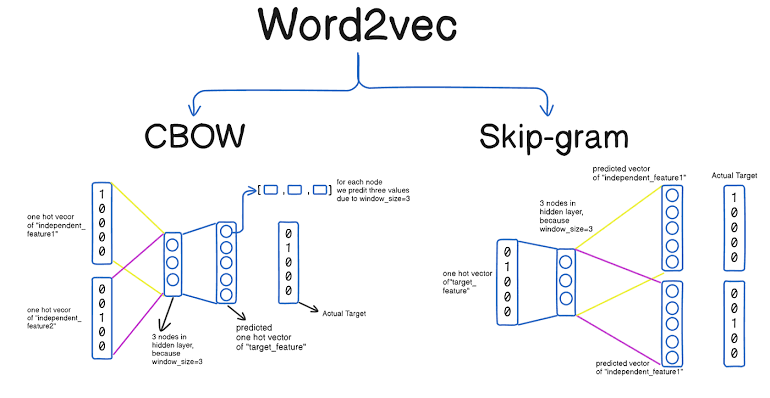

In [1039]:
sentences = [s.split() for s in train['processed']]
w2v_model = Word2Vec(sentences, vector_size=100, window=5, min_count=1, workers=1, epochs=50, seed=42)
print('Word2Vec Vocabulary Size:', len(w2v_model.wv))

Word2Vec Vocabulary Size: 4407


### Khảo sát từ vựng đã học trong mô hình Word2Vec

In [1040]:
print("100 từ đầu:", w2v_model.wv.index_to_key[:100])
print("100 từ cuối:", w2v_model.wv.index_to_key[-100:])

100 từ đầu: ['có', 'mình', 'em', 'ạ', 'học', 'k', 'bạn', '1', 'nhé', 'đi', 'b', 'token_lienhe', '2', 'e', 'mà', 'ko', 'đc', 'để', 'không', 'còn', 'người', 'nha', 'vào', 'trường', 'cũng', 'thôi', 'cần', 'đâu', 'nào', 'rồi', 'lại', '3', 'ơi', 'thi', 'phải', 'tham_gia', 'xin', 'lên', 'hay', 'anh', 'token_sdt', 'điểm', '4', 'gì', 'nên', 'mới', 'cái', 'năm', 'r', 'mấy', 'ra', 'clb', 'làm', 'cứ', 'sẽ', 'nhiều', 'luôn', 'đến', 'chưa', 'như', 'trong', 'vậy', 'đấy', 'hỏi', 'đang', 'thấy', 'pass', 'ai', 'ptit', 'nếu', 'xem', 'sao', 'ẩn_danh', 'chỉ', 'đã', 'qua', 'về', 'c', 'tìm', 'sau', 'phòng', 'trên', 'cô', 'đây', 'nhưng', 'aptis', 'cả', 'lớp', 'có_thể', 'từ', 'lấy', 'hơn', 'muốn', 'toeic', 'hết', 'chứ', 'à', 'nữa', '5', 'chị']
100 từ cuối: ['khỏe_ác', 'công_nghêj', 'hog', 'thời_hạn', 'sấm', 'vịt', 'sx', 'xanh', 'oiw', 'bajn', 'nhieeu', 'ụa', 'choaa', 'emm', 'sỡ', 'sàm', 'kiện', '4000', 'xác_xuất', 'thực_lực', 'cho_phép', 'soáy', 'bảo_mai', 'saoo', 'dồ', 'vs_triết', 'alo', 'ngoong', 'cột', '36

### Minh họa vector embedding của 1 từ cụ thể

In [1041]:
word = w2v_model.wv.index_to_key[36]
print("Từ:", word)
print("Vector:", w2v_model.wv[word])
print("Shape:", w2v_model.wv[word].shape)


Từ: xin
Vector: [ 0.21944089  0.3825253   0.17536846  0.25960615  0.77981895 -0.8580638
 -0.33071843  0.2856904  -0.4493685  -0.41793203 -0.63319016  0.3500691
  0.33768255 -0.74774754  0.5489438  -1.1183033   0.10347273 -0.89147323
 -0.5419127  -0.5831843   0.01381693 -0.16290273 -0.82407653  0.87904644
  1.3104492   0.21921374 -0.44868597 -0.12613092 -0.12830101 -0.4799289
 -0.8814959  -0.3407357  -1.193483    0.44519165  0.8813092  -1.6470597
 -0.34006798 -1.7666953  -0.42323998  0.433432    0.4263205   0.6714227
  1.439107    0.3354524  -0.28422505 -0.4431891   0.7828451   1.4658309
  1.397851    0.5067934  -1.2719492  -1.6989688  -0.14487523  0.41985884
  1.3026834  -1.2335596   0.10729098  0.55074275 -0.9390952   0.04464871
  0.36173964 -0.40559396  0.5242565   0.5913949   0.6747271  -0.5134707
  0.55950594 -1.8218423   0.564927   -0.484995   -0.25427464 -0.9858923
  0.66866136 -1.4437294  -0.4328116  -0.7879335  -0.25540847  0.27067882
 -0.14014432 -0.48446366  0.7788231  -1.168

### Biểu diễn bình luận bằng trung bình cộng vector từ (Word2Vec Average Pooling)
* Vector đại diện của cả bình luận được tính bằng:
  $$\mathbf{d}_{avg} = \frac{1}{|V_d|} \sum_{w \in V_d} \mathbf{v}_w$$

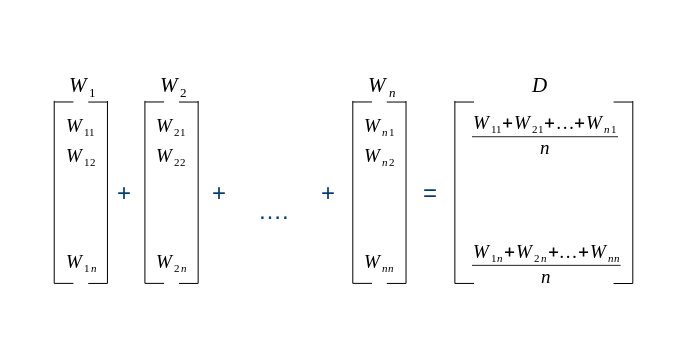

In [1042]:
def doc_vector_avg(tokens):
    vecs = [w2v_model.wv[w] for w in tokens if w in w2v_model.wv]
    return np.mean(vecs, axis=0) if len(vecs) > 0 else np.zeros(w2v_model.vector_size)

X_train_w2v_avg = np.array([doc_vector_avg(s.split()) for s in train['processed']])
X_test_w2v_avg = np.array([doc_vector_avg(s.split()) for s in test['processed']])

### Trích xuất mẫu vector Word2Vec Average

In [1043]:
print("Processed:", train.iloc[36]["processed"])
print("Vector Word2Vec Avg:", X_train_w2v_avg[36])
print("Shape:", X_train_w2v_avg[36].shape)
np.savetxt("out/vector_w2v_avg.txt", X_train_w2v_avg[36], fmt="%.6f")

Processed: em có_thể tham_khảo aptis nha aptis dễ nhất rùi em học trong thời_gian ngắn thi đc em cần tham_khảo nhắn_sốp nha
Vector Word2Vec Avg: [ 6.52533650e-01 -1.29041910e-01 -3.93886805e-01 -1.27737835e-01
  7.43741542e-02 -2.73189098e-01 -1.62630621e-02 -2.13674959e-02
 -8.16763937e-01  3.91289666e-02 -1.44924140e+00  4.81471062e-01
  4.19478863e-01  8.88160706e-01 -7.35959649e-01 -9.13778841e-01
  5.17236888e-01 -6.58845425e-01 -5.12762010e-01 -3.18829387e-01
  2.94669461e-03  3.13680142e-01  1.24797061e-01  8.60186338e-01
  3.08063179e-01 -1.74495056e-01 -5.17524481e-01  1.54266864e-01
 -9.55379382e-02 -8.34072828e-01  4.49724287e-01  2.86860228e-01
 -2.57849753e-01 -4.36487934e-03 -2.96157956e-01 -1.08995676e-01
  2.35841006e-01 -4.20726001e-01 -4.79996949e-01  2.23118231e-01
  2.83146918e-01  4.81197715e-01  1.15327549e+00  1.54417619e-01
 -3.25976908e-01  4.56145294e-02 -1.37044877e-01  4.96179938e-01
  1.91837624e-01 -6.11409843e-01  4.36374128e-01 -1.28329408e+00
  7.076004

### Biểu diễn bình luận bằng Word2Vec có trọng số TF-IDF (IDF-Weighted Pooling)
* Trọng số hóa IDF nhằm gán mức độ quan trọng cao hơn cho các từ khóa mang tính phân biệt:
  $$\mathbf{d}_{weighted} = \frac{\sum_{w \in V_d} idf(w) \cdot \mathbf{v}_w}{\sum_{w \in V_d} idf(w)}$$

In [1044]:
tfidf_uni = TfidfVectorizer(ngram_range=(1, 1), min_df=1)
tfidf_uni.fit(train['processed'])
idf_dict = dict(zip(tfidf_uni.get_feature_names_out(), tfidf_uni.idf_))

def doc_vector_tfidf_avg(tokens):
    vecs, weights = [], []
    for w in tokens:
        if w in w2v_model.wv:
            weight = idf_dict.get(w, 1.0)
            vecs.append(w2v_model.wv[w] * weight)
            weights.append(weight)
    return np.sum(vecs, axis=0) / sum(weights) if (len(vecs) > 0 and sum(weights) > 0) else np.zeros(w2v_model.vector_size)

X_train_w2v_tfidf = np.array([doc_vector_tfidf_avg(s.split()) for s in train['processed']])
X_test_w2v_tfidf = np.array([doc_vector_tfidf_avg(s.split()) for s in test['processed']])


### Minh họa trọng số IDF của các từ trong một bình luận mẫu

In [1045]:
for w in train.iloc[36]["processed"].split():
    if w in w2v_model.wv:
        print(f"{w}: {idf_dict.get(w, 1.0):.4f}")

em: 3.2383
có_thể: 5.0161
tham_khảo: 5.7782
aptis: 5.0500
nha: 4.0353
aptis: 5.0500
dễ: 5.5269
nhất: 5.5269
rùi: 6.3378
em: 3.2383
học: 3.4268
trong: 4.7797
thời_gian: 5.8146
ngắn: 7.7241
thi: 4.3742
đc: 3.9064
em: 3.2383
cần: 4.2201
tham_khảo: 5.7782
nhắn_sốp: 6.8078
nha: 4.0353


### Trích xuất mẫu vector Word2Vec có trọng số IDF

In [1046]:
print("Vector Word2Vec có trọng số:", X_train_w2v_tfidf[36])
print("Shape:", X_train_w2v_tfidf[36].shape)
np.savetxt("out/vector_w2v_weighted.txt", X_train_w2v_tfidf[36], fmt="%.6f")

Vector Word2Vec có trọng số: [ 0.59335397 -0.15590939 -0.40658096 -0.11973853  0.05388691 -0.21804705
  0.02531472  0.02729993 -0.81708367  0.05187813 -1.37677726  0.44787967
  0.39968419  0.86029353 -0.74347138 -0.90336549  0.53690316 -0.66565262
 -0.45172213 -0.32575324 -0.02791012  0.3181218   0.12225179  0.81982274
  0.31562332 -0.1875124  -0.50723293  0.17331995 -0.04938674 -0.82943646
  0.4787592   0.24558252 -0.22696329 -0.01544162 -0.26390393 -0.13476763
  0.21804796 -0.4185294  -0.49177779  0.22530227  0.28289809  0.46759303
  1.19978291  0.1240097  -0.33324861  0.07113496 -0.14087676  0.51272655
  0.17586134 -0.56015695  0.44375868 -1.26237287  0.01611742 -0.93366443
  0.90291594  0.17739886 -1.14497575 -0.54062541  0.24157503  0.33485019
  0.95567296 -0.10988467  0.49481526 -0.4676438   0.37946868  1.0226541
  0.18661824 -0.78813393 -0.23910506  0.58720456 -0.00962989 -0.01522019
 -0.21320966  0.32184128 -0.15048607 -0.27040926 -0.36168324  0.75746741
 -0.00378787 -0.0537467

### Không gian đặc trưng kết hợp Hybrid (TF-IDF + Word2Vec)
* Ghép nối (concatenate) vector thưa TF-IDF n-gram và vector đặc Word2Vec thành vector đa góc nhìn:
  $$\mathbf{X}_{hybrid} = [\mathbf{X}_{TF-IDF} \,\|\, \mathbf{X}_{W2V\_TFIDF}]$$

In [1047]:
X_train_combined = hstack([X_train_tfidf, X_train_w2v_tfidf]).tocsr()
X_test_combined = hstack([X_test_tfidf, X_test_w2v_tfidf]).tocsr()
print('Hybrid Features Size:', X_train_combined.shape[1])

Hybrid Features Size: 4517


## 4. Huấn Luyện Mô Hình (Model Training)
* Khởi tạo các thuật toán học máy phân loại văn bản:
  1. **MultinomialNB (Multinomial Naive Bayes)**: Phù hợp với đặc trưng tần số đếm rời rạc (BoW, TF-IDF).
  <br>
  <img src="https://databasecamp.de/wp-content/uploads/naive-bayes-overview-1024x709.png" width="400" />
  
  2. **LinearSVC (Linear Support Vector Classifier)**: Tối ưu cho không gian đặc trưng nhiều chiều, sử dụng tham số `class_weight='balanced'` để tự động điều chỉnh trọng số bù đắp hiện tượng mất cân bằng lớp (data imbalance).
  <br>
  <img src="https://machinelearningcoban.com/assets/19_svm/svm3.png" width="400" />

In [1048]:
multinomialNB = MultinomialNB()
linearSVC = LinearSVC(
    dual='auto', class_weight='balanced',
    C=1.0, max_iter=3000, random_state=42
)

### Huấn luyện đa mô hình trên các không gian đặc trưng
* Thực hiện huấn luyện song song các tổ hợp giữa phương pháp biểu diễn (BoW, TF-IDF, Word2Vec Avg, Word2Vec Weighted, Hybrid) và thuật toán phân loại.

In [1049]:
experiments = {
    ('BoW', 'MultinomialNB'): (X_train_bow, X_test_bow, multinomialNB),
    ('BoW', 'LinearSVC'): (X_train_bow, X_test_bow, linearSVC),
    ('TF-IDF', 'MultinomialNB'): (X_train_tfidf, X_test_tfidf, multinomialNB),
    ('TF-IDF', 'LinearSVC'): (X_train_tfidf, X_test_tfidf, linearSVC),
    ('Word2Vec Avg', 'LinearSVC'): (X_train_w2v_avg, X_test_w2v_avg, linearSVC),
    ('Word2Vec TF-IDF Avg', 'LinearSVC'): (X_train_w2v_tfidf, X_test_w2v_tfidf, linearSVC),
    ('TF-IDF + Word2Vec', 'LinearSVC'): (X_train_combined, X_test_combined, linearSVC)
}

results = []
predictions = {}

for (feat, algo), (X_tr, X_te, clf) in experiments.items():
    clf.fit(X_tr, train['label'])
    y_pred = clf.predict(X_te)
    predictions[(feat, algo)] = y_pred

    results.append({
        'Feature': feat,
        'Model': algo,
        'Accuracy': accuracy_score(test['label'], y_pred),
        'Precision macro': precision_score(test['label'], y_pred, average='macro', zero_division=0),
        'Recall macro': recall_score(test['label'], y_pred, average='macro', zero_division=0),
        'Precision spam': precision_score(test['label'], y_pred, pos_label='spam', zero_division=0),
        'Recall spam': recall_score(test['label'], y_pred, pos_label='spam', zero_division=0),
        'F1 spam': f1_score(test['label'], y_pred, pos_label='spam', zero_division=0),
        'Macro F1': f1_score(test['label'], y_pred, average='macro', zero_division=0),
    })

## 5. Đánh Giá Mô Hình (Model Evaluation)

### Bảng tổng hợp so sánh kết quả thực nghiệm (Benchmark Results)
* Đánh giá hiệu năng dựa trên các chỉ số đánh giá:
  * **Accuracy**: Độ chính xác tổng thể trên toàn bộ tập test.
  * **Precision / Recall / F1 (Spam)**: Năng lực nhận diện chính xác lớp rác/spam.
  * **Macro F1**: Trung bình cộng không trọng số giữa F1 của 2 lớp, là thước đo khách quan nhất đối với dữ liệu lệch nhãn.

In [1050]:
scores_df = pd.DataFrame(results)
scores_df

,Feature,Model,Accuracy,Precision macro,Recall macro,Precision spam,Recall spam,F1 spam,Macro F1
0,BoW,MultinomialNB,0.937575,0.886808,0.840896,0.820000,0.706897,0.759259,0.861699
1,BoW,LinearSVC,0.927971,0.859924,0.828091,0.769231,0.689655,0.727273,0.842889
2,TF-IDF,MultinomialNB,0.909964,0.941537,0.680337,0.976744,0.362069,0.528302,0.739267
3,TF-IDF,LinearSVC,0.932773,0.864925,0.848946,0.772727,0.732759,0.752212,0.856662
4,Word2Vec Avg,LinearSVC,0.887155,0.767952,0.869415,0.563218,0.844828,0.675862,0.803774
5,Word2Vec TF-IDF Avg,LinearSVC,0.882353,0.760278,0.855787,0.552326,0.818966,0.659722,0.794302
6,TF-IDF + Word2Vec,LinearSVC,0.935174,0.860172,0.875631,0.754098,0.793103,0.773109,0.867647


### Trực quan hóa so sánh Macro F1 giữa các cấu hình

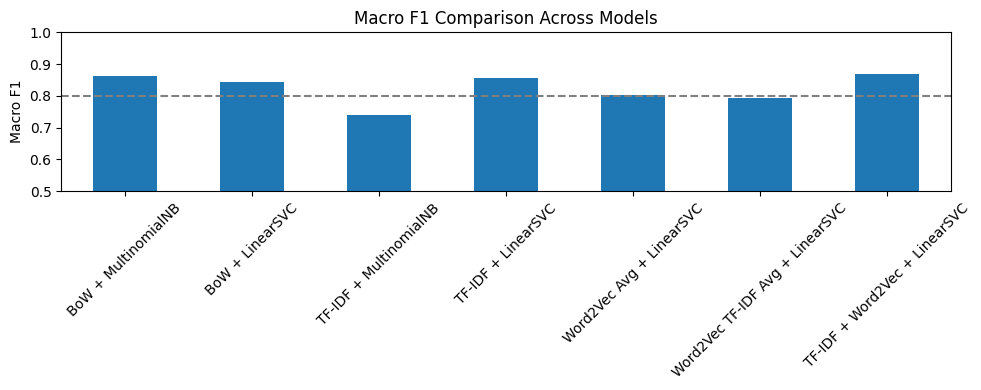

In [1051]:
model_names = scores_df['Feature'] + ' + ' + scores_df['Model']
scores_df.set_index(model_names)['Macro F1'].plot(kind='bar', figsize=(10, 4), rot=45)
plt.axhline(0.8, color='gray', linestyle='--')
plt.title('Macro F1 Comparison Across Models')
plt.ylabel('Macro F1')
plt.ylim(0.5, 1.0)
plt.tight_layout()
plt.show()

### Đánh giá chi tiết mô hình tối ưu (Best Model Evaluation)

In [1052]:
best_model = tuple(scores_df.loc[scores_df['Macro F1'].idxmax(), ['Feature', 'Model']])
print("Mô hình có Macro F1 cao nhất:", best_model)

Mô hình có Macro F1 cao nhất: ('TF-IDF + Word2Vec', 'LinearSVC')


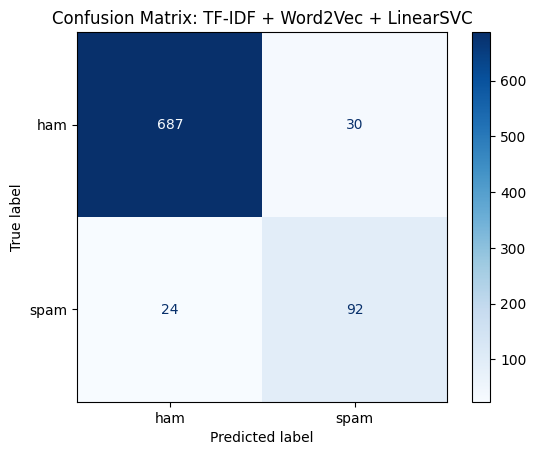

In [1053]:
cm = confusion_matrix(test['label'], predictions[best_model], labels=['ham', 'spam'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['ham', 'spam'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix: ' + best_model[0] + ' + ' + best_model[1])
plt.show()

* **Báo cáo phân loại chi tiết (Classification Report)**:

In [1054]:
print(classification_report(test['label'], predictions[best_model], digits=4))

              precision    recall  f1-score   support

         ham     0.9662    0.9582    0.9622       717
        spam     0.7541    0.7931    0.7731       116

    accuracy                         0.9352       833
   macro avg     0.8602    0.8756    0.8676       833
weighted avg     0.9367    0.9352    0.9359       833



### Phân tích lỗi (Error Analysis)
* Trích xuất và kiểm tra các trường hợp mô hình phân loại sai ($y_{true} \neq y_{pred}$) để xác định nguyên nhân gốc rễ (nhãn gán nhiễu, câu mập mờ, hoặc từ vựng mới phát sinh ngoài từ điển).

In [1055]:
review = test[['content', 'label']].copy()
review['pred'] = predictions[best_model]
review[review['label'] != review['pred']].head(10)

,content,label,pred
2988,"Vị trí thuận tiện: Ngay ngã tư Trương Văn Thành và Tân Hoà 2, P. Hiệp Phú cũ.",spam,ham
3255,Báo giá học phí trọn gói,spam,ham
1219,- NƯỚC 36.300/1khối,spam,ham
2390,Mình cần cc để quy đổi học phần tiếng anh nhắn sốp nha,spam,ham
1410,"Olympic AI sinh viên năm nay, trường mình vẫn đang trong giai đoạn chọn đội tuyển nên sẽ chưa có bạn nào liên hệ em đâu. Nếu em cần tài liệu/định hướng có thể liên hệ thầy qua mail: cuongpd@ptit.edu.vn.",ham,spam
2069,Mình dư áo khiacs thể thao size l còn mới trong bọc,ham,spam
3138,Matcha latte/ Coconut matcha/ Matcha latte xoài/dâu/ Matcha kem xoài/dâu / Matcha caramel muối . 17-24K,spam,ham
3884,B lh 0977.202.733 k nhận hậu tạ đâu ạ,ham,spam
1504,Bỏ ẩn danh ra để t ib đê,ham,spam
2160,Cứu dc r nhé ai cần thì để số mình chỉ qua zalo cho,spam,ham


### Đánh giá trên tập kiểm thử cân bằng (Balanced Test Evaluation)
* Tiến hành lấy mẫu ngẫu nhiên (undersampling) lớp Ham để tạo tập test có tỷ lệ 1:1 với lớp Spam.

In [1056]:
test_spam = test[test['label'] == 'spam']
test_ham = test[test['label'] == 'ham'].sample(n=len(test_spam), random_state=42)
test_balanced = pd.concat([test_spam, test_ham]).sample(frac=1.0, random_state=42)

idx_balanced = [test.index.get_loc(i) for i in test_balanced.index]
preds_bal = predictions[best_model][idx_balanced]

print(test_balanced['label'].value_counts())
print('Accuracy: ', round(accuracy_score(test_balanced['label'], preds_bal), 4))
print('Macro F1: ', round(f1_score(test_balanced['label'], preds_bal, average='macro'), 4))
print(classification_report(test_balanced['label'], preds_bal, digits=4))

label
ham     116
spam    116
Name: count, dtype: int64
Accuracy:  0.875
Macro F1:  0.8742
              precision    recall  f1-score   support

         ham     0.8222    0.9569    0.8845       116
        spam     0.9485    0.7931    0.8638       116

    accuracy                         0.8750       232
   macro avg     0.8853    0.8750    0.8742       232
weighted avg     0.8853    0.8750    0.8742       232



* Ma trận nhầm lẫn trên tập test cân bằng:

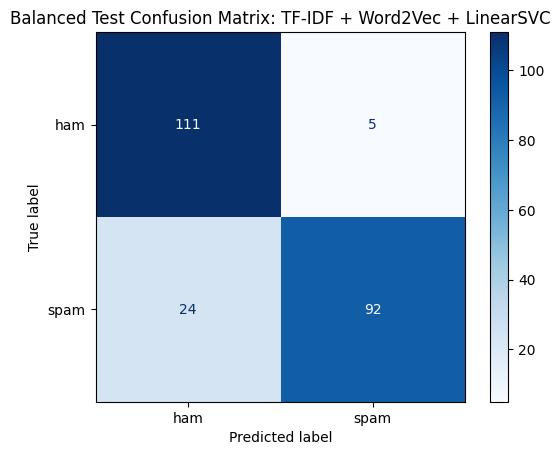

In [1057]:
cm_bal = confusion_matrix(test_balanced['label'], preds_bal, labels=['ham', 'spam'])
disp_bal = ConfusionMatrixDisplay(confusion_matrix=cm_bal, display_labels=['ham', 'spam'])
disp_bal.plot(cmap='Blues')
plt.title('Balanced Test Confusion Matrix: ' + best_model[0] + ' + ' + best_model[1])
plt.show()